# 8-2. 점예측·계수 비교

세 모델(AR단독 / AR+GARCH 동시 / AR+SV 동시)을 같은 조건으로 놓고, 동시최적화가 점예측과 계수를 바꾸는지 본다. `8-3`~`8-5`의 기준 파이프라인이다.

- **조건**: 세 모델 모두 AR(1)(MA 없음), d=1, 22개 origin. (d,p)는 `8-4`에서 검증한다.
- **계수 추정**: 계수(AR계수 φ, GARCH의 ω·α·β, SV의 phi·σ_η)는 origin마다 훈련 데이터에 **최대우도추정(MLE)으로 fit**한다. 구조(d, p)만 사람이 정한다.
- **σ 전파**: h단계 σ는 `level_sigma`(정확한 공식)로 계산한다. 수준 오차는 `Σ ε_(t+i) x ψ_(h-i)`로 쌓이므로 분산이 `Σ ψ_(h-i)² x (i단계 오차분산)`이다.
- **드리프트 없음**: 세 모델 모두 상수항·평균 복원이 없다. 이유는 다음과 같다.
  - 평균식 조건을 통일하기 위해서다. GARCH(`arch` 기본값 Const)·SV(평균 제거)·AR단독의 드리프트가 서로 달랐다.
  - 데이터가 랜덤워크에 가까워(자기상관 0.93) 추세를 가정할 근거가 약하고, 표본이 작아(20~56개) 드리프트를 추정하면 예측 분산만 커진다.
  - 이 표본에서는 없는 쪽이 성능이 좋았다(`8-6(참고)`: GARCH CRPS 0.604 -> 0.588, SV 0.591 -> 0.576, AR단독은 넣으면 0.593 -> 0.618). 다만 22개 origin이 겹쳐 유의성은 검증하지 않았다.
  - **한계**: d=0에서는 상수항이 수준의 평균이라, 빼면 예측이 0으로 끌려간다. `8-4`의 d=0 결과는 절편 없는 설정 기준이다.
- 초기 버전의 σ 전파 오류·드리프트 비교 조건 불일치는 `8-6(참고)`, `결함판(참고용)/`에 있다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats
from scipy.optimize import minimize

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
MODEL_NAMES = ["AR단독", "GARCH동시", "SV동시"]

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
var_std = vals.std()
scored_origins = list(range(MIN_TRAIN, len(vals) - H + 1))[INITIAL_CALIB:]
print(f"채점 origin {len(scored_origins)}개")


채점 origin 22개


## 1. 수정된 세 모델 함수

`d`, `p`를 일반화해서 `level_sigma`가 모든 (d,p)에서 동작하고, 드리프트는 없다. (함수는 `8-3`~`8-5`와 같은 코드 -- 노트북 하나로 완결되게 다시 정의했다.)


In [2]:
def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


def level_sigma(ar_coefs, d, innov_var):
    # ARIMA(p,d,0)의 h단계 수준 예측오차 표준편차: 오차 eps_(t+i)가 psi_(h-i)배로 쌓인다
    # (psi = AR 충격반응을 d번 누적합). innov_var[i] = (i+1)단계 오차분산 예측.
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def ar_forecast(train, d, p):
    m = pm.ARIMA(order=(p, d, 0), with_intercept=False, suppress_warnings=True).fit(train)
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    par = dict(zip(m.arima_res_.model.param_names, m.arima_res_.params))
    ar = [par[f"ar.L{k}"] for k in range(1, p + 1)]
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z), {"ar1": ar[0] if p else np.nan}


def garch_forecast(train, d, p):
    diff_train, hist = difference(train, d)
    if len(diff_train) <= p + 3:
        return None
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    try:
        res = am.fit(disp="off")
    except Exception:
        return None
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, d)
    sig = level_sigma(ar, d, f.residual_variance.values[-1])
    return fc, sig, {"ar1": ar[0] if p else np.nan, "omega": res.params["omega"], "alpha": res.params["alpha[1]"], "beta": res.params["beta[1]"]}


def sv_forecast(train, d, p):
    y, hist = difference(train, d)
    if len(y) <= p + 3:
        return None
    res = minimize(joint_sv_negloglik, [0.0] * p + [1.5, np.log(0.3)], args=(y, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        return None
    ar, phi, s2 = res.x[:p], MAX_PHI * np.tanh(res.x[p]), np.exp(res.x[p + 1]) ** 2
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(y[-p:]) if p else []
    mean_diff = []
    for _ in range(H):
        pred = sum(ar[i] * past[-1 - i] for i in range(p))
        mean_diff.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** k * hf + (phi ** (2 * k) * Pf + s2 * sum(phi ** (2 * j) for j in range(k))) / 2)
         for k in range(1, H + 1)]
    return undiff_mean(mean_diff, hist, d), level_sigma(ar, d, v), {"ar1": ar[0] if p else np.nan, "phi_logvol": phi, "sigma_eta": np.sqrt(s2)}


FORECASTERS = {"AR단독": ar_forecast, "GARCH동시": garch_forecast, "SV동시": sv_forecast}


def run(d, p):
    rows, infos = [], []
    for origin in scored_origins:
        train, actual = vals[:origin], vals[origin:origin + H]
        for name, fn in FORECASTERS.items():
            try:
                out = fn(train, d, p)
            except Exception:
                out = None
            if out is None:
                continue
            fc, sig, info = out
            infos.append({"d": d, "p": p, "모델": name, "origin": origin, **info})
            for h in range(H):
                rows.append({"d": d, "p": p, "모델": name, "origin": origin, "h": h + 1, "fc": fc[h],
                             "sigma": max(sig[h], 1e-6), "actual": actual[h]})
    return pd.DataFrame(rows), pd.DataFrame(infos)


def add_scores(df):
    df = df.copy()
    df["z"] = (df["actual"] - df["fc"]) / df["sigma"]
    df["cov"] = (df["z"].abs() <= Z) * 100.0
    df["mse"] = ((df["actual"] - df["fc"]) / var_std) ** 2
    df["crps"] = ps.crps_gaussian(df["actual"], mu=df["fc"], sig=df["sigma"]) / var_std
    return df


def summarize(df, keys=("모델",)):
    return df.groupby(list(keys)).agg(커버리지=("cov", "mean"), MSE=("mse", "mean"), CRPS=("crps", "mean")).round(3)


## 2. 성능과 재현 확인

일반화한 함수가 `8-6(참고)`(d=1, p=1 전용으로 짠 코드)의 결과(σ 수정 + 드리프트 없음)를 재현하는지 확인한다.


In [3]:
det_raw, info_df = run(1, 1)
det = add_scores(det_raw)

expected = pd.DataFrame({"커버리지": [65.909, 73.864, 64.773], "MSE": [1.128, 1.080, 1.052], "CRPS": [0.593, 0.582, 0.578]},
                        index=pd.Index(MODEL_NAMES, name="모델"))
check = summarize(det).join(expected, lsuffix="_재계산", rsuffix="_8-6참고")
display(check)
print("최대 차이:", float((summarize(det) - expected).abs().max().max()))


,커버리지_재계산,MSE_재계산,CRPS_재계산,커버리지_8-6참고,MSE_8-6참고,CRPS_8-6참고
모델,,,,,,
AR단독,65.909,1.128,0.593,65.909,1.128,0.593
GARCH동시,73.864,1.080,0.582,73.864,1.080,0.582
SV동시,64.773,1.052,0.578,64.773,1.052,0.578


최대 차이: 0.0


## 3. 세 모델의 계수 (22개 origin 평균 ± 표준편차)


In [4]:
cols = ["ar1", "omega", "alpha", "beta", "phi_logvol", "sigma_eta"]
display(info_df.groupby("모델")[cols].agg(["mean", "std"]).round(3).T)


모델                AR단독  GARCH동시   SV동시
ar1        mean  0.492    0.425 -0.056
           std   0.055    0.077  0.008
omega      mean    NaN  490.687    NaN
           std     NaN  356.145    NaN
alpha      mean    NaN    0.257    NaN
           std     NaN    0.257    NaN
beta       mean    NaN    0.673    NaN
           std     NaN    0.317    NaN
phi_logvol mean    NaN      NaN  0.845
           std     NaN      NaN  0.067
sigma_eta  mean    NaN      NaN  0.409
           std     NaN      NaN  0.033

## 4. 점예측이 실제로 다른가

두 모델 점예측 차이의 평균 / `var_std`이고, 차이가 1e-6 미만이면 동일로 본다.

In [5]:
w = det.pivot_table(index=["origin", "h"], columns="모델", values="fc")
pairs = {"|AR-GARCH|": ("AR단독", "GARCH동시"), "|AR-SV|": ("AR단독", "SV동시"), "|GARCH-SV|": ("GARCH동시", "SV동시")}
gap = pd.DataFrame({k: {"평균 정규화 차이": (w[a] - w[b]).abs().mean() / var_std,
                        "동일 비율(%)": 100 * ((w[a] - w[b]).abs() < 1e-6).mean()} for k, (a, b) in pairs.items()}).round(3)
display(gap)


,|AR-GARCH|,|AR-SV|,|GARCH-SV|
평균 정규화 차이,0.064,0.315,0.254
동일 비율(%),0.000,0.000,0.000


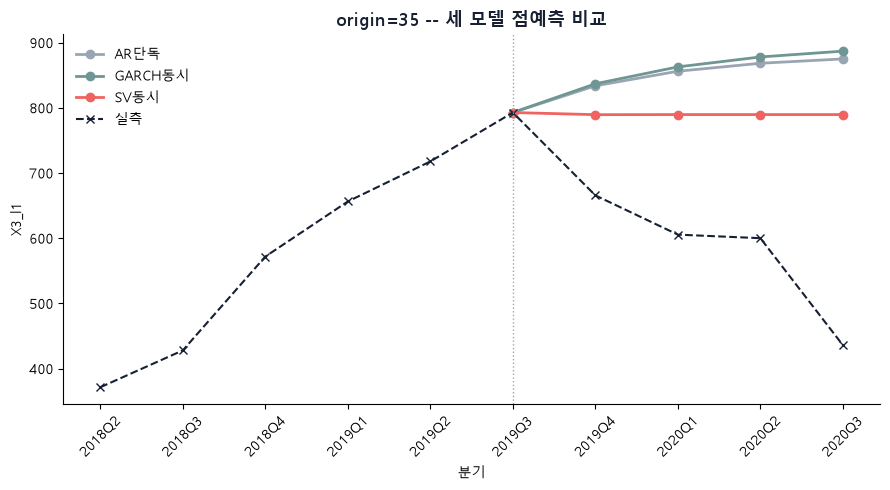

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

quarters = raw[["quarter", "X3_l1"]].dropna()["quarter"].reset_index(drop=True).values
example_origin, LOOKBACK = scored_origins[0], 6
ex = det[det["origin"] == example_origin]
hist_idx = list(range(example_origin - LOOKBACK, example_origin + H))
colors_m = {"AR단독": "#9AA5B4", "GARCH동시": "#6F9692", "SV동시": "#EF6461"}

fig, ax = plt.subplots(figsize=(9, 5))
anchor_idx, anchor_v = example_origin - 1, vals[example_origin - 1]
for name, color in colors_m.items():
    sub = ex[ex["모델"] == name].sort_values("h")
    ax.plot([anchor_idx] + list(range(example_origin, example_origin + H)), [anchor_v] + list(sub["fc"]),
            marker="o", linewidth=2, label=name, color=color)
ax.plot(hist_idx, vals[example_origin - LOOKBACK: example_origin + H], marker="x", linewidth=1.5, linestyle="--",
        color="#172033", label="실측")
ax.axvline(anchor_idx, color="#9AA5B4", linewidth=1, linestyle=":")
ax.set_xticks(hist_idx)
ax.set_xticklabels(quarters[hist_idx])
ax.set_xlabel("분기")
ax.set_ylabel("X3_l1")
ax.tick_params(axis="x", rotation=45)
ax.set_title(f"origin={example_origin} -- 세 모델 점예측 비교", fontsize=13, fontweight="bold", color="#172033")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 5. 계수 진단 -- 경계해와 분산 지속성


In [7]:
sv = info_df[info_df["모델"] == "SV동시"]
g = info_df[info_df["모델"] == "GARCH동시"]
n = len(sv)
corner = (sv["phi_logvol"].abs() >= MAX_PHI * 0.999) | (sv["sigma_eta"] < 0.01)
print(f"SV동시: phi가 경계(|phi|>={MAX_PHI * 0.999:.3f})이거나 sigma_eta<0.01인 origin {corner.sum()}/{n}개 ({100 * corner.mean():.1f}%)")
print(f"SV동시 AR계수 평균: 코너해 {sv.loc[corner, 'ar1'].mean():.3f} / 정상 {sv.loc[~corner, 'ar1'].mean():.3f}")
persist = g["alpha"] + g["beta"]
print(f"GARCH동시: alpha+beta>=0.99 origin {(persist >= 0.99).sum()}/{len(g)}개 ({100 * (persist >= 0.99).mean():.1f}%)")


SV동시: phi가 경계(|phi|>=0.969)이거나 sigma_eta<0.01인 origin 0/22개 (0.0%)
SV동시 AR계수 평균: 코너해 nan / 정상 -0.056
GARCH동시: alpha+beta>=0.99 origin 11/22개 (50.0%)


## 6. h별 σ 보정 진단

h별 z 표준편차(z=(실제-예측)/σ, 1에 가까울수록 σ가 맞음)를 본다.


In [8]:
print("h별 z 표준편차:")
display(det.groupby(["모델", "h"])["z"].std().unstack("h").round(2))


h별 z 표준편차:


h,1,2,3,4
모델,,,,
AR단독,2.11,2.19,2.18,2.11
GARCH동시,2.06,2.10,2.03,1.94
SV동시,1.67,2.12,2.33,2.41


## 7. `MAX_PHI` 민감도

phi 상한 0.97은 검증하지 않은 값이라, 평균 제거 없는 이 파이프라인에서 상한을 바꾸면 SV동시 성능이 변하는지 다시 확인한다.


In [9]:
sens_rows = []
for mp in [0.90, 0.95, 0.97, 0.99]:
    MAX_PHI = mp
    rows, hit = [], 0
    for origin in scored_origins:
        train, actual = vals[:origin], vals[origin:origin + H]
        fc, sig, info = sv_forecast(train, 1, 1)
        hit += abs(info["phi_logvol"]) >= mp * 0.999
        for h in range(H):
            rows.append({"모델": "SV동시", "fc": fc[h], "sigma": max(sig[h], 1e-6), "actual": actual[h]})
    s = summarize(add_scores(pd.DataFrame(rows))).iloc[0]
    sens_rows.append({"MAX_PHI": mp, "커버리지": s["커버리지"], "MSE": s["MSE"], "CRPS": s["CRPS"], "경계도달": f"{hit}/{len(scored_origins)}"})
MAX_PHI = 0.97
display(pd.DataFrame(sens_rows))


,MAX_PHI,커버리지,MSE,CRPS,경계도달
0,0.90,65.909,1.052,0.577,9/22
1,0.95,64.773,1.052,0.578,0/22
2,0.97,64.773,1.052,0.578,0/22
3,0.99,64.773,1.052,0.578,0/22


## 8. 결론

d=1, p=1, 22개 origin:

| 모델 | 커버리지(%) | MSE | CRPS |
|---|---|---|---|
| AR단독 | 65.9 | 1.128 | 0.593 |
| GARCH동시 | 73.9 | 1.080 | 0.582 |
| SV동시 | 64.8 | 1.052 | 0.578 |

- **세 모델의 점예측은 100% 다르다**(동일 0%). |AR-SV|가 0.315로 가장 크고, SV의 AR계수는 -0.056으로 0 근처다(AR단독 0.49, GARCH 0.43).
- **SV 코너해 0/22**, phi 0.85±0.07, σ_η 0.41±0.03으로 안정적이다.
- **CRPS 순위**: SV 0.578 < GARCH 0.582 < AR 0.593. 최선은 SV지만 차이는 작다.
- **σ 과소**: 커버리지가 64.8~73.9%로 목표 90%에 못 미친다. SV의 σ는 h가 커질수록 덜 자란다(z 표준편차 1.67 -> 2.41).
- **phi 상한(0.97)은 고정해도 무방하다(7절)**: 0.95~0.99에서 결과가 같다.